In [53]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pypulseq as pp
import MRzeroCore as mr0
import torchkbnufft as tkbn
from pypulseq import Sequence
from tqdm import tqdm
from typing import Optional, Tuple
from Modules.Plan import KbNufft, KbNufftAdjoint
from Modules.FourierTransform import nonuniform_fourier_transform_forward, nonuniform_fourier_transform_adjoint
import Modules.ConcatSum 
from Modules.Regularizer import Regularizer
from Modules.CoilSens import cyclic_head_coil 
from Modules.Linops import LinearOperator, ChannelOperator, IdentityOperator
from Modules.NumSolvers import conjugate_gradient
import Modules.Resnet

/tmp/ipykernel_2337/664300643.py:26: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf, gz, _ = pp.make_sinc_pulse(


Timing check passed successfully


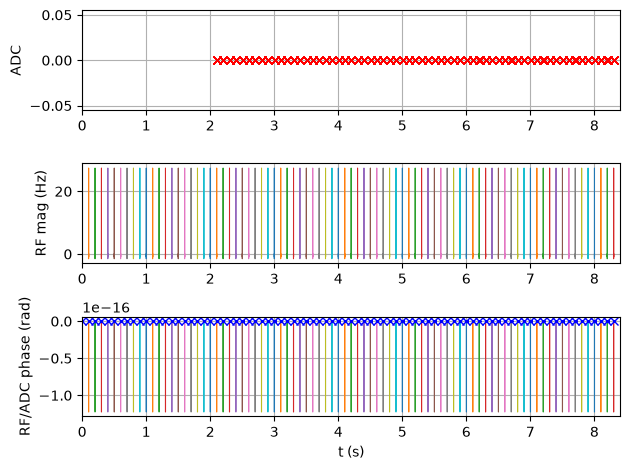

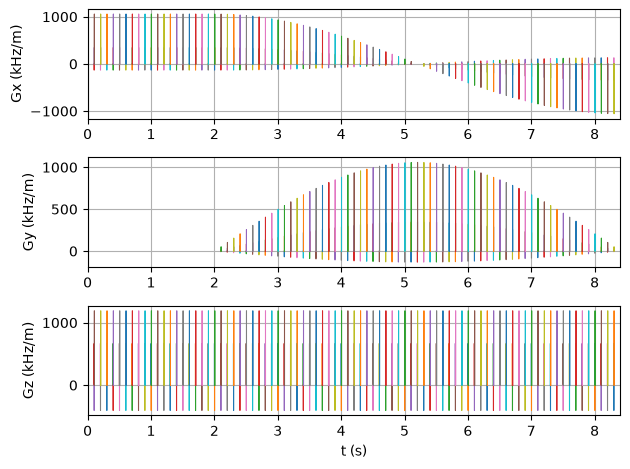

In [60]:
def main(plot: bool, write_seq: bool, seq_filename: str = "gre_radial_pypulseq.seq"):
    seq = pp.Sequence()  
    fov = 360e-3
    Nx = 160 
    alpha = 5 
    R = 4
    slice_thickness = 3e-3  
    TE = 4e-3 
    TR = 100e-3  
    Nr = 256  
    N_dummy = 20  
    delta = np.pi / Nr  

    rf_spoiling_inc = 117 

    system = pp.Opts(
        max_grad=28,
        grad_unit="mT/m",
        max_slew=120,
        slew_unit="T/m/s",
        rf_ringdown_time=20e-6,
        rf_dead_time=100e-6,
        adc_dead_time=10e-6,
    )

    rf, gz, _ = pp.make_sinc_pulse(
        apodization=0.5,
        duration=2e-3,
        flip_angle=alpha * np.pi / 180,
        slice_thickness=slice_thickness,
        system=system,
        time_bw_product=4,
        return_gz=True,
    )

    deltak = 1 / fov
    gx = pp.make_trapezoid(
        channel="x", flat_area=Nx * deltak, flat_time=6.4e-3 / 5, system=system
    )
    adc = pp.make_adc(
        num_samples=Nx, duration=gx.flat_time, delay=gx.rise_time, system=system
    )
    gx_pre = pp.make_trapezoid(
        channel="x", area=-gx.area / 2, duration=2e-3, system=system
    )
    gz_reph = pp.make_trapezoid(
        channel="z", area=-gz.area / 2, duration=2e-3, system=system
    )
    gx_spoil = pp.make_trapezoid(channel="x", area=0.5 * Nx * deltak, system=system)
    gz_spoil = pp.make_trapezoid(channel="z", area=4 / slice_thickness, system=system)
    
    delay_TE = (
        np.ceil(
            (
                TE
                - pp.calc_duration(gx_pre)
                - gz.fall_time
                - gz.flat_time / 2
                - pp.calc_duration(gx) / 2
            )
            / seq.grad_raster_time
        )
        * seq.grad_raster_time
    )
    delay_TR = (
        np.ceil(
            (
                TR
                - pp.calc_duration(gx_pre)
                - pp.calc_duration(gz)
                - pp.calc_duration(gx)
                - delay_TE
            )
            / seq.grad_raster_time
        )
        * seq.grad_raster_time
    )
    assert np.all(delay_TR) > pp.calc_duration(gx_spoil, gz_spoil)
    rf_phase = 0
    rf_inc = 0

    angles = np.linspace(0, np.pi, Nr // R , endpoint=False)

    for i in range(-N_dummy, Nr // R):

        if i < 0:
            angle = 0
        else:
            angle = angles[i]
    
        seq.add_block(rf, gz)
        seq.add_block(*pp.rotate(gx_pre, gz_reph, angle=angle, axis="z"))
        seq.add_block(pp.make_delay(delay_TE))
        if i > 0:
            seq.add_block(*pp.rotate(gx, adc, angle=angle, axis="z"))
        else:
            seq.add_block(*pp.rotate(gx, angle=angle, axis="z"))
        seq.add_block(
            *pp.rotate(gx_spoil, gz_spoil, pp.make_delay(delay_TR), angle=angle, axis="z")
        )

    ok, error_report = seq.check_timing()
    if ok:
        print("Timing check passed successfully")
    else:
        print("Timing check failed! Error listing follows:")
        print(error_report)

    if plot:
        seq.plot()

    if write_seq:
        seq.set_definition("FOV", [fov, fov, slice_thickness])
        seq.set_definition("Name", "gre_rad")
        seq.write("Radial 2D GRE")


if __name__ == "__main__":
    main(plot=True, write_seq=True)

In [61]:
Nx = 160
n_channels = 8
fov = 360e-3

phantom = mr0.util.load_phantom(size=(Nx, Nx))

coil_sensitivities_recon = cyclic_head_coil((n_channels, Nx, Nx, 1)).to(torch.complex64)
coil_sensitivities_recon = coil_sensitivities_recon.flip((1, 2))
coil_sensitivities_recon = coil_sensitivities_recon[..., 0]

coil_sensitivities_sim = cyclic_head_coil(
    (n_channels, Nx, Nx, 1),
    fov_scaling=(phantom.size[0] / fov, phantom.size[1] / fov, 1),
).to(torch.complex64)
phantom.coil_sens = coil_sensitivities_sim   # ← must happen before build()/simulate

data = phantom.build()
mr0_seq = mr0.Sequence.import_file("Radial 2D GRE.seq")
graph = mr0.compute_graph(mr0_seq, data)
signal = mr0.execute_graph(graph, mr0_seq, data, print_progress=True)

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.001525716 s
Compute Graph
Computing Graph: 0.017081335 s
Analyze Graph
Analyzing Graph: 0.000851698 s
Converting Rust -> Python: 0.012124936 s
<<<< Rust <<<<


Calculating repetitions:   0%|          | 0/84 [00:00<?, ?it/s]

Done.


In [38]:
ktraj_raw = mr0_seq.get_kspace()[:, :2].T
ktraj_torch = torch.tensor(ktraj_raw).float()
k_max = ktraj_torch.abs().max()
ktraj_torch = (ktraj_torch / k_max)
ktraj_torch = ktraj_torch.unsqueeze(0)
adjnufft_ob = tkbn.KbNufftAdjoint(im_size=(320, 320), grid_size=(640, 640)).to(ktraj_torch.device)
rho = torch.sqrt(ktraj_torch[:, 0, :]**2 + ktraj_torch[:, 1, :]**2).unsqueeze(1)
dcomp = (rho / rho.max())
hanning = 0.5 + 0.5 * torch.cos(rho / rho.max())
dcomp_smooth = dcomp * hanning
kspace = signal.view(1, 1, -1)
kspace_real = kspace * dcomp_smooth
reco = adjnufft_ob(kspace_real, ktraj_torch)
reco_fixed = torch.rot90(reco.squeeze(), k=1, dims=(0, 1))
vmax = np.percentile(torch.abs(reco_fixed).numpy(), 99.99)
plt.axis('off')
plt.figure(figsize=(6, 6))
plt.imshow(torch.abs(reco_fixed), cmap='gray', vmin=0, vmax=vmax)
plt.title("2D Radial GRE Reconstruction")
plt.axis('off')
plt.show()

/tmp/ipykernel_2337/2616571636.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  ktraj_torch = torch.tensor(ktraj_raw).float()


RuntimeError: The size of tensor a (162560) must match the size of tensor b (20320) at non-singleton dimension 2

In [62]:
class DeepADMM(nn.Module):

    def __init__(self, shape, rho_init=0.1, maxiter_admm=10, maxiter_cg=5):

        super().__init__()
        self.rho = nn.Parameter(torch.tensor(rho_init, dtype=torch.float32))
        self.regularizer = Regularizer(shape)
        self.I = IdentityOperator(shape)
        self.maxiter_admm = maxiter_admm
        self.maxiter_cg = maxiter_cg

    def forward(self,Q,b,x, disable_progressbar=True):
        z = torch.zeros(self.I.shape[0], dtype=x.dtype)
        u = torch.zeros(self.I.shape[0], dtype=x.dtype)

        for iteration in range(self.maxiter_admm):
    
            x = conjugate_gradient(
                Q + self.rho * self.I,
                b=b + self.rho * (z - u),
                x=x,
                maxiter=self.maxiter_cg,
                disable_progressbar=True,
            )
    
            z = self.regularizer(x + u)
            u = u + x - z
    
        return x

VoxelGridPhantom
size = tensor([0.2000, 0.2000, 0.0080])
Plotting 1st of 8 coil sens maps


/opt/conda/lib/python3.13/site-packages/matplotlib/cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)


<Figure size 640x480 with 0 Axes>

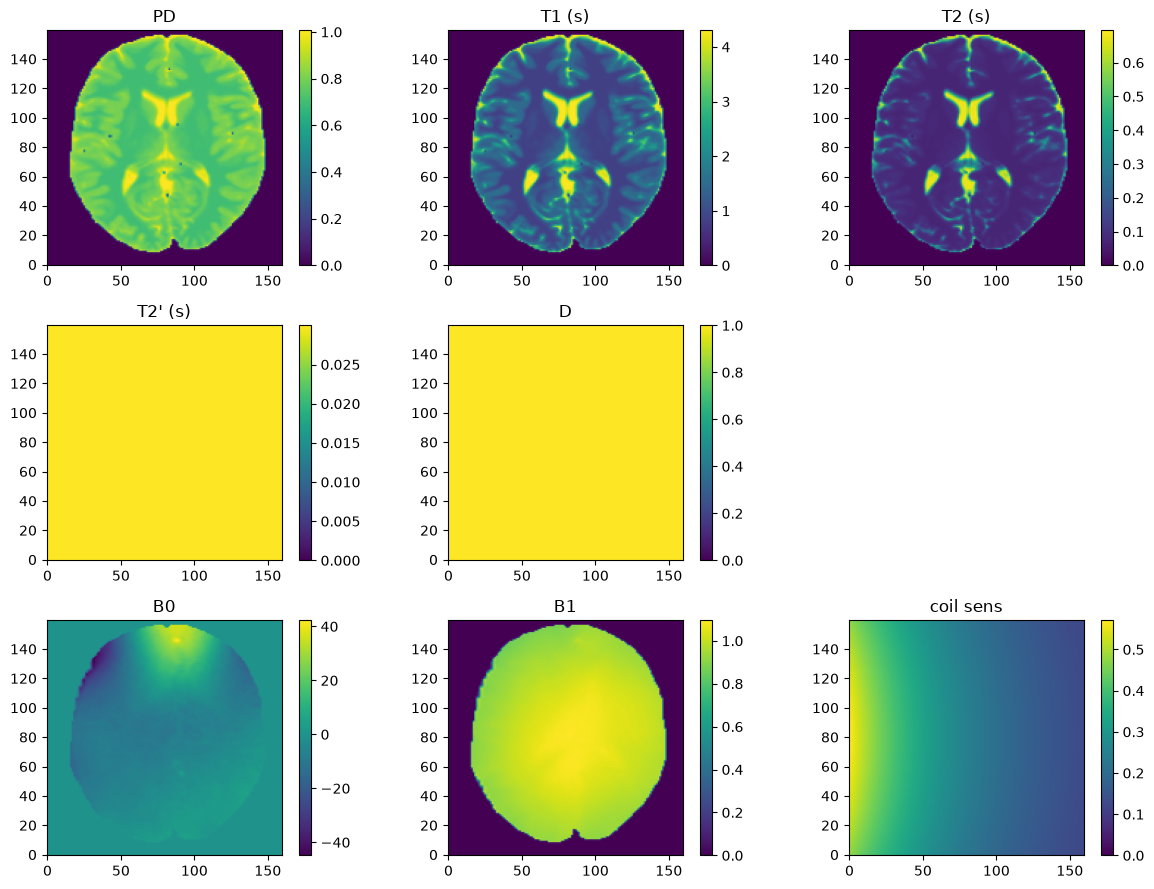

In [63]:
fov = 360e-3
coil_sensitivities_sim = cyclic_head_coil(
    (n_channels, Nx, Nx, 1),
    fov_scaling=(phantom.size[0] / fov, phantom.size[1] / fov, 1),
).to(torch.complex64)
phantom.coil_sens = coil_sensitivities_sim

plt.figure()
phantom.plot()

In [64]:
class NonuniformFourierTransformOperator(LinearOperator):

    def __init__(
        self,
        k: torch.Tensor,
        input_shape: Tuple[int, ...],
        device: Optional[torch.device] = None,
    ):
        nD, nK = k.shape
        nC, nX, nY = input_shape

        self.n_modes = (nX, nY)
        self.k = k
        self.forward_shape = (nC, nX, nY, 1)
        self.adjoint_shape = (nC, nK)
        self.shape = (
            int(2 * torch.prod(torch.tensor(self.adjoint_shape))),
            int(2 * torch.prod(torch.tensor(self.forward_shape))),
        )
        self.nufft_ob = KbNufft(im_size=self.n_modes).to(device)
        self.adj_ob = KbNufftAdjoint(im_size=self.n_modes).to(device)

        self.dtype = torch.float32
        self.device = device

    def _matvec(self, x: torch.Tensor) -> torch.Tensor:
        x = torch.view_as_complex(x.reshape(-1, 2)).reshape(self.forward_shape)
        y = nonuniform_fourier_transform_forward(self.k, x, nufft_ob=self.nufft_ob)
        return torch.view_as_real(y.reshape(-1)).reshape(-1)

    def _rmatvec(self, x: torch.Tensor) -> torch.Tensor:
        x = torch.view_as_complex(x.reshape(-1, 2)).reshape(self.adjoint_shape)
        y = nonuniform_fourier_transform_adjoint(
            self.k, x, self.n_modes, adj_ob=self.adj_ob
        )
        return torch.view_as_real(y.reshape(-1)).reshape(-1)

seq = pp.Sequence()
seq.read("Radial 2D GRE.seq")
kspace = seq.calculate_kspace()
k_traj_adc = kspace[0]
k_traj_adc = k_traj_adc[:2, :]
k_traj_radius = np.sqrt(np.sum(k_traj_adc**2, axis=0, keepdims=True))
k_traj_adc = k_traj_adc / k_traj_radius.max() * 0.5
k_traj_adc = torch.tensor(k_traj_adc, dtype=torch.float32)

F = NonuniformFourierTransformOperator(k_traj_adc, (n_channels, Nx, Nx))
C = ChannelOperator(coil_sensitivities_recon, (Nx, Nx))
A = F @ C

In [40]:
print("signal shape:", signal.shape)
print("signal.numel():", signal.numel())

signal shape: torch.Size([20320, 8])
signal.numel(): 162560


In [65]:
data = signal.clone()
data = data.reshape((-1, n_channels)).permute((1, 0))
data = data.contiguous()
AHd = A.H @ data.view(torch.float32).ravel()
AHd_image = AHd.view(torch.complex64).reshape((Nx, Nx))
Q = A.H @ A
b = AHd
x = torch.zeros(Nx * Nx, dtype=torch.complex64).view(torch.float32)
x_recon = conjugate_gradient(Q, b, x, maxiter=30)
x_recon_image = x_recon.view(torch.complex64).reshape((Nx, Nx))

  0%|          | 0/30 [00:00<?, ?it/s]

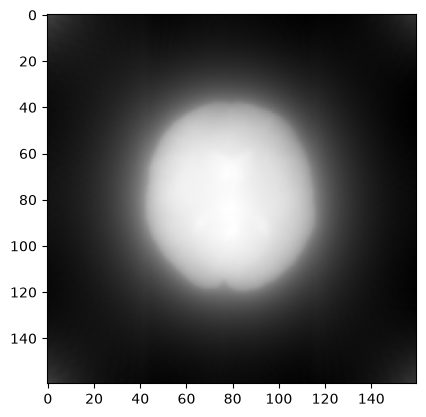

In [66]:
plt.figure()
plt.imshow(torch.abs(AHd_image).numpy().T, cmap="gray")
plt.show()

In [67]:
Nx = 160
torch.manual_seed(0)
shape = (Nx, Nx, 1)
model_init = DeepADMM(shape, rho_init=0.1, maxiter_admm=10, maxiter_cg=5)

with torch.no_grad():
    x_deep_admm_init = model_init(Q, b, b)
x_deep_admm_init_image = x_deep_admm_init.view(torch.complex64).reshape((Nx, Nx))

In [68]:
shape = (Nx, Nx, 1)

torch.manual_seed(0)
model = DeepADMM(
    shape,
    rho_init=0.1,
    maxiter_admm=10,
    maxiter_cg=5,
)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

nK = k_traj_adc.shape[1]
num_splits = 25

model.train()
losses = []

progress_bar = tqdm(range(num_splits), desc="Self-supervised splits")

for split in progress_bar:

    np.random.seed(split)

    indices = np.arange(nK)
    np.random.shuffle(indices)
    index_src, index_tar = np.split(indices, 2)

    k_traj_src = k_traj_adc[:, index_src]
    k_data_src = data[:, index_src].view(torch.float32).ravel()

    k_traj_tar = k_traj_adc[:, index_tar]
    k_data_tar = data[:, index_tar].view(torch.float32).ravel()

    F_src = NonuniformFourierTransformOperator(k_traj_src, (n_channels, Nx, Nx))
    F_tar = NonuniformFourierTransformOperator(k_traj_tar, (n_channels, Nx, Nx))
    C = ChannelOperator(coil_sensitivities_recon, (Nx, Nx))

    Q_src = C.H @ F_src.H @ F_src @ C
    b_src = C.H @ F_src.H @ k_data_src

    x_out = model(Q_src, b_src, b_src, disable_progressbar=True)

    k_data_pred = F_tar @ C @ x_out

    loss = torch.linalg.norm(k_data_pred - k_data_tar, ord=1) / torch.linalg.norm(
        k_data_tar, ord=1
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    progress_bar.set_postfix(loss=f"{loss.item():.4f}")

Self-supervised splits: 100%|██████████| 25/25 [09:50<00:00, 23.61s/it, loss=0.0856]


In [69]:
model.eval()
F_full = NonuniformFourierTransformOperator(k_traj_adc, (n_channels, Nx, Nx))
C = ChannelOperator(coil_sensitivities_recon, (Nx, Nx))
x0 = torch.zeros(Nx * Nx, dtype=torch.complex64).view(torch.float32)
with torch.no_grad():
    x_deep_admm_trained = model(Q, b, b)

x_deep_admm_trained_image = x_deep_admm_trained.view(torch.complex64).reshape(
    (Nx, Nx)
)

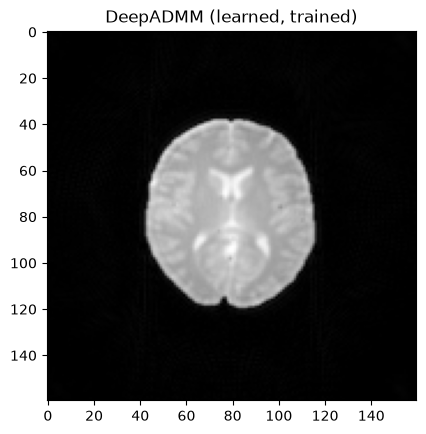

In [70]:
plt.imshow(torch.abs(x_deep_admm_trained_image).numpy().T, cmap="gray")
plt.title("DeepADMM (learned, trained)")
plt.show()

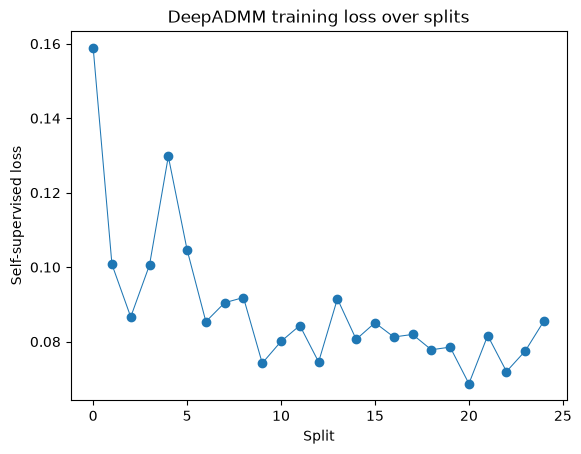

In [71]:
plt.figure()
plt.plot(losses, marker="o")
plt.xlabel("Split")
plt.ylabel("Self-supervised loss")
plt.title("DeepADMM training loss over splits")
plt.show()